# 7. Predictive Analysis — Classification
This notebook trains logistic regression, SVM, decision tree and KNN classifiers. It uses the one-hot encoded course dataset when available.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("https://raw.githubusercontent.com/chuksoo/IBM-Data-Science-Capstone-SpaceX/main/dataset_part_3.csv")
print("Shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Shape: (90, 76)


,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_GEO,Orbit_GTO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Orbit_GEO', 'Orbit_GTO', 'Orbit_HEO', 'Orbit_ISS', 'Orbit_LEO', 'Orbit_MEO', 'Orbit_PO', 'Orbit_SO', 'Orbit_SSO', 'Orbit_VLEO', 'LaunchSite_KSC LC 39A', 'LaunchSite_VAFB SLC 4E', 'LandingPad_5e9e3032383ecb554034e7c9', 'LandingPad_5e9e3032383ecb6bb234e7ca', 'LandingPad_5e9e3032383ecb761634e7cb', 'LandingPad_5e9e3033383ecbb9e534e7cc', 'Serial_B0005', 'Serial_B0007', 'Serial_B1003', 'Serial_B1004', 'Serial_B1005', 'Serial_B1006', 'Serial_B1007', 'Serial_B1008', 'Serial_B1010', 'Serial_B1011', 'Serial_B1012', 'Serial_B1013', 'Serial_B1015', 'Serial_B1016', 'Serial_B1017', 'Serial_B1018', 'Serial_B1019', 'Serial_B1020', 'Serial_B1021', 'Serial_B1022', 'Serial_B1023', 'Serial_B1025', 'Serial_B1026', 'Serial_B1028', 'Serial_B1029', 'Serial_B1030', 'Serial_B1031', 'Serial_B1032', 'Serial_B1034', 'Serial_B1035', 'Serial_B1036', 'Serial_B1037', 'Serial_B1038', 'Serial_B1039', 'Serial_B1040', 'Serial

In [4]:


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

base_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/"

# Load processed features
X = pd.read_csv(base_url + "dataset_part_3.csv")

# Load original records to construct the target
original = pd.read_csv(base_url + "dataset_part_1.csv")

# Verify that both datasets have matching row counts
if len(X) != len(original):
    raise ValueError(
        f"Row counts do not match: features={len(X)}, original={len(original)}"
    )

# Create landing-success target from original outcomes
y = original["Outcome"].astype(str).str.startswith("True").astype(int)

# Prepare features
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2,
    stratify=y
)

print("Feature dataset shape:", X.shape)
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Feature count:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts().sort_index())


Feature dataset shape: (90, 83)
Training records: 72
Test records: 18
Feature count: 83

Target distribution:
Outcome
0    30
1    60
Name: count, dtype: int64



 Logistic Regression
Best parameters: {'model__C': 0.1}
Test accuracy: 0.7778
              precision    recall  f1-score   support

           0       0.75      0.50      0.60         6
           1       0.79      0.92      0.85        12

    accuracy                           0.78        18
   macro avg       0.77      0.71      0.72        18
weighted avg       0.77      0.78      0.76        18



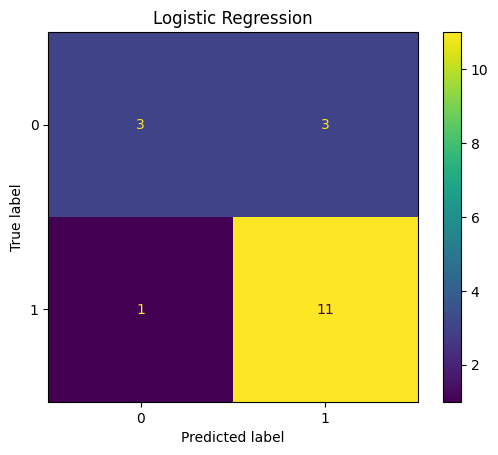


 SVM
Best parameters: {'model__C': 1, 'model__kernel': 'sigmoid'}
Test accuracy: 0.8333
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       0.80      1.00      0.89        12

    accuracy                           0.83        18
   macro avg       0.90      0.75      0.78        18
weighted avg       0.87      0.83      0.81        18



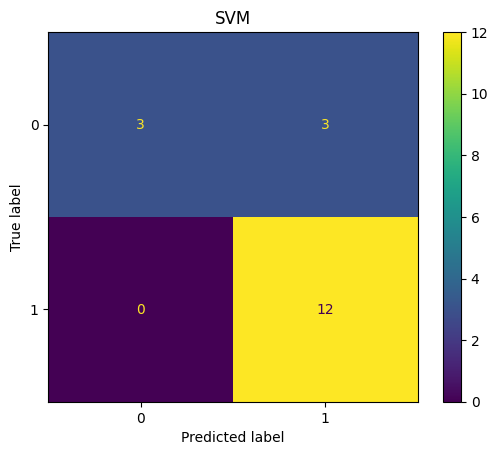


 Decision Tree
Best parameters: {'max_depth': 2, 'min_samples_split': 2}
Test accuracy: 0.7778
              precision    recall  f1-score   support

           0       0.62      0.83      0.71         6
           1       0.90      0.75      0.82        12

    accuracy                           0.78        18
   macro avg       0.76      0.79      0.77        18
weighted avg       0.81      0.78      0.78        18



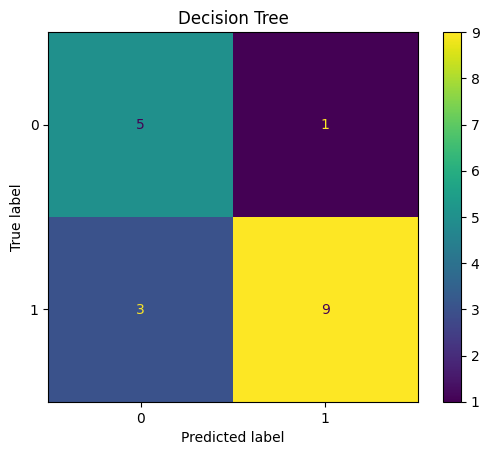


 KNN
Best parameters: {'model__n_neighbors': 5}
Test accuracy: 0.6667
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         6
           1       0.67      1.00      0.80        12

    accuracy                           0.67        18
   macro avg       0.33      0.50      0.40        18
weighted avg       0.44      0.67      0.53        18



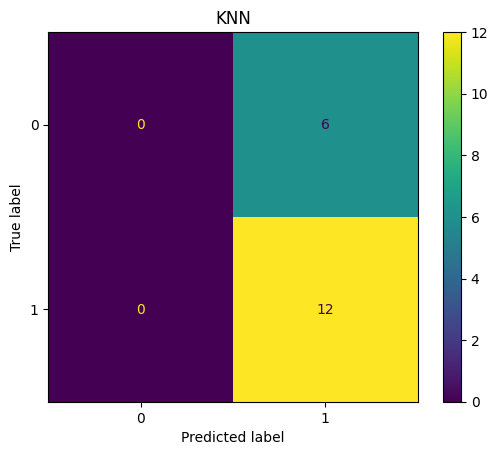

,Model,Best CV accuracy,Test accuracy,Best parameters
1,SVM,0.862857,0.833333,"{'model__C': 1, 'model__kernel': 'sigmoid'}"
0,Logistic Regression,0.848571,0.777778,{'model__C': 0.1}
2,Decision Tree,0.862857,0.777778,"{'max_depth': 2, 'min_samples_split': 2}"
3,KNN,0.793333,0.666667,{'model__n_neighbors': 5}


In [5]:
# Scale numeric features for LR, SVM and KNN. Tree does not require scaling.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=2),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", __import__("sklearn.neighbors").neighbors.KNeighborsClassifier())
    ])
}
params = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "SVM": {"model__kernel": ["linear", "rbf", "sigmoid"], "model__C": [0.1, 1, 10]},
    "Decision Tree": {"max_depth": [2, 4, 6, 8, None], "min_samples_split": [2, 5, 10]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9]}
}
results = []
best_models = {}
for name, model in models.items():
    grid = GridSearchCV(model, params[name], cv=5, scoring="accuracy", n_jobs=-1)
    grid.fit(X_train, y_train)
    pred = grid.predict(X_test)
    acc = accuracy_score(y_test, pred)
    best_models[name] = grid.best_estimator_
    results.append({"Model": name, "Best CV accuracy": grid.best_score_,
                    "Test accuracy": acc, "Best parameters": grid.best_params_})
    print("\n", name)
    print("Best parameters:", grid.best_params_)
    print("Test accuracy:", round(acc, 4))
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name)
    plt.show()

results_df = pd.DataFrame(results).sort_values("Test accuracy", ascending=False)
display(results_df)

In [6]:
results_df.to_csv("model_comparison_results.csv", index=False)
print("Saved model_comparison_results.csv")
print("Use the actual output above in your presentation; results may differ from the course's first run if the data or split differs.")

Saved model_comparison_results.csv
Use the actual output above in your presentation; results may differ from the course's first run if the data or split differs.


## Interpretation
Report the test-set size, best validation/CV hyperparameters, test accuracy, and confusion matrix. Do not copy an accuracy value from another repository if it differs from your own run.